# NSBI reproduction — path B (own CARL networks)

**What this notebook does.** Loads the two path-B CARL classifiers ($p_{\rm sig}/p_{\rm bkg}$ and
$p_{\rm sbi}/p_{\rm bkg}$), forms the $\mu$-dependent density-ratio mixture, and builds the NSBI
$-2\Delta\ln L$ scan — first **as-is** (shape-only, reproducing Tei's committed 300 fb$^{-1}$ curve),
then **with the extended Poisson rate term added** (the fix), then swept over luminosity to test the
Asimov-property failure (Asimov ≠ median of toys at 1–10 fb$^{-1}$).

**Status of inputs.** `sig_over_bkg` trained well (val 0.419); `sbi_over_bkg` is the beefed-up retrain
(the first attempt sat at the random floor — see `docs/nsbi-reproduction.md`). Inference is done on
**CPU** here (plain forward passes), so no GPU is needed to run this notebook.

**How to use.** Run top to bottom. Parameters in one cell; plotting cells separated. Reference curves
(Tei's committed NSBI scans, 300 fb$^{-1}$) are read from `output/reference_tei/`. Companion:
`notebooks/histogram_reproduction.ipynb` (the histogram baseline this is compared against).

## 1. Imports (CPU inference)

In [1]:
import os, sys, json, glob, pickle
import numpy as np, torch
import matplotlib.pyplot as plt

ROOT = os.environ.get('SBI_ROOT', '/project/atlas/Users/mfernand/SBI_shortcomings')
SUBREPO = os.path.join(ROOT, 'asimov-aymptotics-check')
if SUBREPO not in sys.path: sys.path.insert(0, SUBREPO)
from models.carl import CARL
from physics.simulation import toys
torch.set_default_dtype(torch.float32)
print('engine:', SUBREPO)

engine: /project/atlas/Users/mfernand/SBI_shortcomings/asimov-aymptotics-check


## 2. Parameters

In [2]:
RUN      = os.path.join(ROOT, 'output/nsbi-pathB/h4l')   # holds sig_over_bkg/ and sbi_over_bkg/
DATA_DIR = os.environ.get('DATASET_DIR', os.path.join(ROOT, 'data/zz4l/ggzz4l_sm'))
REF_DIR  = os.path.join(ROOT, 'output/reference_tei')     # Tei's committed NSBI scans (300 fb^-1)
REF_LUMI = 300.
LUMIS    = [1., 10., 100., 1000.]
N_TOYS   = 200
SEED     = 42
MU_SCAN  = torch.linspace(0.0, 4.0, 101)
C_SIG, C_SBI = 1.0, 1.0        # CARL calibration constants (Tei's committed values)
feats = ['l1_pt','l1_eta','l1_phi','l1_energy','l2_pt','l2_eta','l2_phi','l2_energy',
         'l3_pt','l3_eta','l3_phi','l3_energy','l4_pt','l4_eta','l4_phi','l4_energy']
mu_np = MU_SCAN.numpy()

with open(os.path.join(DATA_DIR, 'ggzz4l_xs.json')) as f: xs = json.load(f)
xs_sig, xs_bkg, xs_int, xs_sbi = (np.prod(xs[k]) for k in ('sig','bkg','int','sbi'))
print(f'cross-sections [fb]: sig={xs_sig:.4f} bkg={xs_bkg:.4f} int={xs_int:.4f} sbi={xs_sbi:.4f}')

cross-sections [fb]: sig=0.3099 bkg=5.9530 int=-0.6064 sbi=5.6565


## 3. Load both classifiers and evaluate the SM density ratios

Both networks are evaluated on the **same** SBI test split (the reference sample for the likelihood),
each with its own fitted scaler. `r = s/(1-s) · C` is the CARL likelihood-ratio trick. Done on CPU.

In [3]:
def latest_ckpt(name):
    g = glob.glob(f'{RUN}/{name}/lightning_logs/version_*/checkpoints/epoch=*-val_loss=*.ckpt')
    return max(g, key=lambda f: int(f.split('epoch=')[1].split('-')[0]))

def load(name):
    m = CARL.load_from_checkpoint(latest_ckpt(name), map_location='cpu').eval()
    sc = pickle.load(open(f'{RUN}/{name}/scaler.pkl','rb'))
    return m, sc

def ratio(model, scaler, X, C):
    with torch.no_grad():
        out = model(torch.tensor(scaler.transform(X), dtype=torch.float32)).squeeze().numpy()
    s = out if (out.min() >= 0 and out.max() <= 1) else 1/(1+np.exp(-out))
    s = np.clip(s, 1e-6, 1-1e-6)
    return torch.tensor(s/(1-s)*C, dtype=torch.float64)

# SBI test split = the events the likelihood is evaluated on (numerator of the sbi/bkg classifier)
events_sbi = pickle.load(open(f'{RUN}/sbi_over_bkg/events_numerator_test.pkl','rb'))
X = events_sbi.kinematics[feats].to_numpy()
w = torch.tensor(events_sbi.weights.to_numpy(), dtype=torch.float64)   # per-event xs weights [fb]

m_sig, sc_sig = load('sig_over_bkg')
m_sbi, sc_sbi = load('sbi_over_bkg')
r_sig = ratio(m_sig, sc_sig, X, C_SIG)     # p_sig/p_bkg   (N,)
r_sbi = ratio(m_sbi, sc_sbi, X, C_SBI)     # p_sbi/p_bkg   (N,)
print(f'N test events = {len(w):,}')
print(f'r_sig/bkg: mean {r_sig.mean():.3f} std {r_sig.std():.3f}')
print(f'r_sbi/bkg: mean {r_sbi.mean():.3f} std {r_sbi.std():.3f}   (near-1 flat => sbi net under-trained)')

N test events = 576,265
r_sig/bkg: mean 1.079 std 2.739
r_sbi/bkg: mean 0.998 std 0.049   (near-1 flat => sbi net under-trained)


## 4. The μ-dependent mixture ratio

$$\frac{p_{\rm SBI}(x\mid\mu)}{p_B(x)} = \frac{(\mu-\sqrt\mu)\,\sigma_S\,r_{S/B} + \sqrt\mu\,\sigma_{\rm SBI}\,r_{{\rm SBI}/B} + (1-\sqrt\mu)\,\sigma_B}{\mu\,\sigma_S + \sqrt\mu\,\sigma_I + \sigma_B}$$
The denominator is $\nu_{\rm tot}(\mu)/L$ — reused for the Poisson term below.

In [4]:
ps = MU_SCAN.to(torch.float64)
m_sig_c = ps - torch.sqrt(ps); m_sbi_c = torch.sqrt(ps); m_bkg_c = 1 - torch.sqrt(ps)
num = (xs_sig*m_sig_c[None,:]*r_sig[:,None] + xs_sbi*m_sbi_c[None,:]*r_sbi[:,None]
       + xs_bkg*m_bkg_c[None,:])                                    # (N,101)
den = xs_sig*ps + xs_int*torch.sqrt(ps) + xs_bkg                    # (101,) = nu_tot(mu)/L
r_mu = num / den[None,:]                                            # (N,101)
print('mixture ratio r_mu shape', tuple(r_mu.shape))

mixture ratio r_mu shape (576265, 101)


## 5. NLL scan — as-is (shape only), vs Tei's committed reference

This is the un-patched NSBI likelihood $-2\sum_i L\,w_i \ln r(x_i\mid\mu)$ at 300 fb$^{-1}$, the same
configuration as Tei's committed scan. Overlaid on his reference (`output/reference_tei/`) to check we
reproduce the *shape and direction*. Bit-exact agreement is not expected (our hyperparameters differ);
the direction (median of toys narrower than Asimov) and rough width are what matter.

Tei ref:  Asimov mu_hat=0.920 w=1.267; median w=1.107
path-B:   Asimov mu_hat=0.080 width=0.175


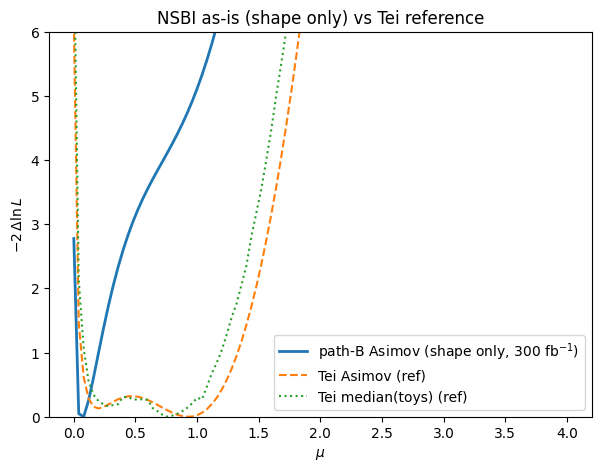

In [5]:
def width(nll):
    d=(nll-nll.min()).numpy(); g=mu_np; i=int(np.argmin(d))
    lo=np.interp(1.0,d[:i+1][::-1],g[:i+1][::-1]) if i>0 and d[:i+1].max()>=1 else np.nan
    hi=np.interp(1.0,d[i:],g[i:]) if i<len(d)-1 and d[i:].max()>=1 else np.nan
    return g[i], (hi-lo)

nll_asimov_shape = -2*torch.sum(REF_LUMI*w[:,None]*torch.log(r_mu), dim=0)   # (101,)

fig,ax=plt.subplots(figsize=(7,5))
da=(nll_asimov_shape-nll_asimov_shape.min())
ax.plot(mu_np, da.numpy(), '-', lw=2, label=f'path-B Asimov (shape only, {REF_LUMI:.0f} fb$^{{-1}}$)')
try:
    ref_mu=torch.load(f'{REF_DIR}/poi_scan.pt',map_location='cpu')
    ref_a=torch.load(f'{REF_DIR}/nll_scan_asimov.pt',map_location='cpu')
    ref_t=torch.load(f'{REF_DIR}/nll_scan_toys.pt',map_location='cpu')
    ax.plot(ref_mu.numpy(),(ref_a-ref_a.min()).numpy(),'--',label="Tei Asimov (ref)")
    refmed=torch.median(ref_t,dim=1).values
    ax.plot(ref_mu.numpy(),(refmed-refmed.min()).numpy(),':',label="Tei median(toys) (ref)")
    print(f"Tei ref:  Asimov mu_hat={width(ref_a)[0]:.3f} w={width(ref_a)[1]:.3f}; median w={width(refmed)[1]:.3f}")
except Exception as e: print('reference not loaded:', e)
mh,wA=width(nll_asimov_shape); print(f"path-B:   Asimov mu_hat={mh:.3f} width={wA:.3f}")
ax.set_xlabel(r'$\mu$'); ax.set_ylabel(r'$-2\,\Delta\ln L$'); ax.set_ylim(0,6); ax.legend()
ax.set_title('NSBI as-is (shape only) vs Tei reference'); plt.show()

## 6. Add the extended Poisson rate term (the fix)

$-2\big(N_{\rm obs}\ln\nu_{\rm tot}(\mu)-\nu_{\rm tot}(\mu)\big)$ with $\nu_{\rm tot}(\mu)=L\cdot{\rm den}$,
$N_{\rm obs}=L\sum_i w_i$ (Asimov). Falsifiable checks: NLL(0) ≠ 0 (was exactly 0 shape-only), and the
Asimov best-fit should move to $\hat\mu=1.000$.

with Poisson term: Asimov mu_hat=0.120 (expect ~1.000), width=0.260
NLL(mu=0) shape-only = 2.777 ; with term = 6.229


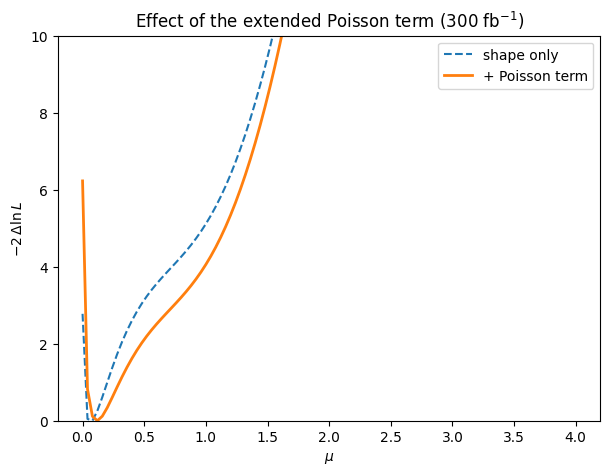

In [6]:
def nll_asimov_full(lumi):
    shape = -2*torch.sum(lumi*w[:,None]*torch.log(r_mu), dim=0)
    nu_tot = lumi*den; N_obs = lumi*w.sum()
    return shape - 2*(N_obs*torch.log(nu_tot) - nu_tot)

nll_full = nll_asimov_full(REF_LUMI)
mh_full,w_full = width(nll_full)
print(f"with Poisson term: Asimov mu_hat={mh_full:.3f} (expect ~1.000), width={w_full:.3f}")
print(f"NLL(mu=0) shape-only = {(nll_asimov_shape[0]-nll_asimov_shape.min()):.3f} ; "
      f"with term = {(nll_full[0]-nll_full.min()):.3f}")
fig,ax=plt.subplots(figsize=(7,5))
ax.plot(mu_np,(nll_asimov_shape-nll_asimov_shape.min()).numpy(),'--',label='shape only')
ax.plot(mu_np,(nll_full-nll_full.min()).numpy(),'-',lw=2,label='+ Poisson term')
ax.set_xlabel(r'$\mu$'); ax.set_ylabel(r'$-2\,\Delta\ln L$'); ax.set_ylim(0,10); ax.legend()
ax.set_title(f'Effect of the extended Poisson term ({REF_LUMI:.0f} fb$^{{-1}}$)'); plt.show()

## 7. Luminosity sweep — Asimov vs median of toys (with Poisson term)

The NSBI counterpart of the histogram figure. Toys: $w_{\rm toy}\sim{\rm Poisson}(w\,L)$ per event;
shape term via the chunk-free matmul $\log r^{\top}\nu_{\rm toy}$ (avoids the 93 GB broadcast).
Expect Asimov ≠ median(toys) at 1–10 fb$^{-1}$, converging by 1000 fb$^{-1}$.

In [7]:
logr = torch.log(r_mu)                       # (N,101) float64
results={}
for L in LUMIS:
    nu_toys = toys.generate(w*L, n_toys=N_TOYS, random_state=SEED).to(torch.float64)  # (N_TOYS,N)
    nu_toys = nu_toys.T                                                                # (N,N_TOYS)
    shape_toys = -2*(logr.T @ nu_toys)                                                 # (101,N_TOYS)
    N_obs_toys = nu_toys.sum(dim=0)                                                     # (N_TOYS,)
    nu_tot = L*den
    nll_toys = shape_toys - 2*(N_obs_toys[None,:]*torch.log(nu_tot)[:,None] - nu_tot[:,None])
    results[L]=dict(asimov=nll_asimov_full(L), toys=nll_toys)
    print(f'{L:>7.0f} fb^-1 done')

/project/atlas/Users/mfernand/SBI_shortcomings/asimov-aymptotics-check/physics/simulation/toys.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  weights = torch.tensor(nu, dtype=torch.float64)


      1 fb^-1 done


     10 fb^-1 done


    100 fb^-1 done


   1000 fb^-1 done


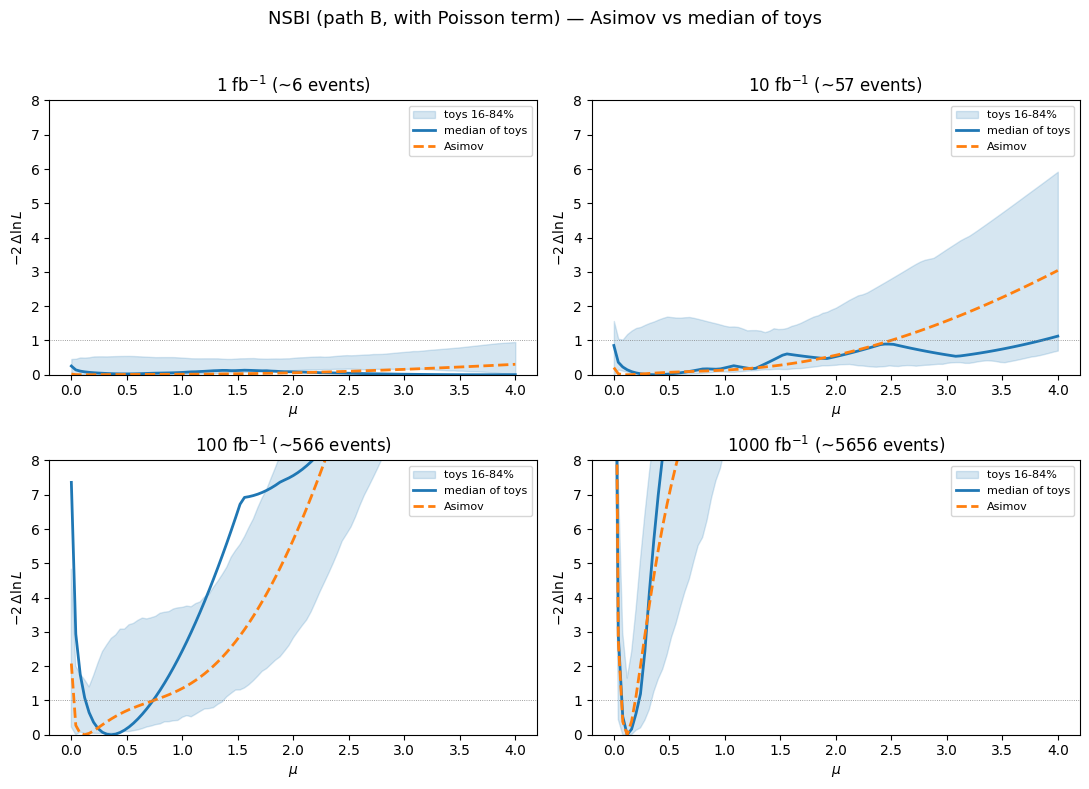

In [8]:
fig,axes=plt.subplots(2,2,figsize=(11,8))
for ax,L in zip(axes.flat,LUMIS):
    r=results[L]; da=(r['asimov']-r['asimov'].min()).numpy()
    tm=r['toys']-r['toys'].min(dim=0).values
    med=torch.median(r['toys'],dim=1).values; dmed=(med-med.min()).numpy()
    lo,hi=torch.quantile(tm,torch.tensor([0.16,0.84],dtype=torch.float64),dim=1).numpy()
    ax.fill_between(mu_np,lo,hi,alpha=0.18,color='C0',label='toys 16-84%')
    ax.plot(mu_np,dmed,'-',color='C0',lw=2,label='median of toys')
    ax.plot(mu_np,da,'--',color='C1',lw=2,label='Asimov')
    ax.axhline(1,color='grey',lw=0.6,ls=':')
    ax.set_title(f'{L:.0f} fb$^{{-1}}$ (~{5.656*L:.0f} events)')
    ax.set_xlabel(r'$\mu$'); ax.set_ylabel(r'$-2\,\Delta\ln L$'); ax.set_ylim(0,8); ax.legend(fontsize=8)
fig.suptitle('NSBI (path B, with Poisson term) — Asimov vs median of toys',fontsize=13)
fig.tight_layout(rect=[0,0,1,0.96]); plt.show()

## 8. Save scans

In [9]:
OUT=os.path.join(ROOT,'output','nsbi-pathB','scans'); os.makedirs(OUT,exist_ok=True)
torch.save(MU_SCAN, f'{OUT}/poi_scan.pt')
torch.save(nll_asimov_shape, f'{OUT}/nll_asimov_shape_only_300fb.pt')
for L in LUMIS:
    torch.save(results[L]['asimov'], f'{OUT}/nll_asimov_full_lumi_{int(L)}.pt')
    torch.save(results[L]['toys'],   f'{OUT}/nll_toys_full_lumi_{int(L)}.pt')
print('saved under', OUT)

saved under /project/atlas/Users/mfernand/SBI_shortcomings/output/nsbi-pathB/scans


## What this shows

*(filled in after execution against the retrained sbi_over_bkg checkpoint)*